# 05 传统视觉：HOG + SVM 与 Haar 级联

**学习目标**：理解“像素 → 手工特征 → 分类器”与“滑动窗口检测”的区别。
本课的主实验使用 scikit-learn 自带的真实手写数字图像，不下载数据。另用 OpenCV 样例照片运行 Haar 人脸检测。
HOG + SVM 是经典特征与分类器组合；Haar + 级联用于演示候选窗口筛选，二者不是同一个算法。

输入：8×8 灰度数字。过程：放大、梯度、方向直方图、SVM。输出：数字类别、测试准确率和失败例。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cpu


## 1. 查看真实输入与矩阵

`load_digits` 的像素范围是 0–16。这里先划分训练/测试集，避免测试信息进入拟合过程。
8×8 是一个极小的教学数据集；它的准确率不能代表真实街景 OCR 性能。


第一张输入的 8×8 像素矩阵：
 [[  0   0  79 207 143  15   0   0]
 [  0   0 207 239 159 239  79   0]
 [  0  47 239  31   0 175 127   0]
 [  0  63 191   0   0 127 127   0]
 [  0  79 127   0   0 143 127   0]
 [  0  63 175   0  15 191 111   0]
 [  0  31 223  79 159 191   0   0]
 [  0   0  95 207 159   0   0   0]]


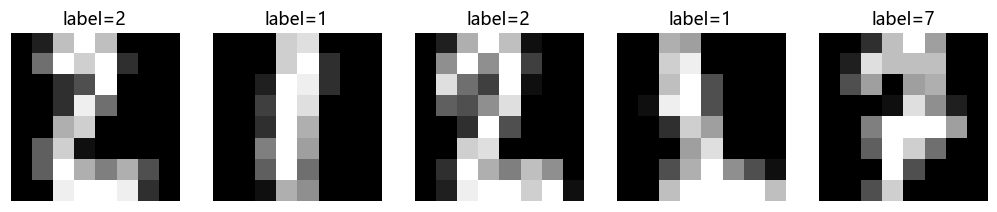

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/05_digit_inputs.png')

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
digits = load_digits()
train_idx, test_idx = train_test_split(np.arange(len(digits.images)), test_size=.25,
                                     random_state=42, stratify=digits.target)
images = (digits.images / 16 * 255).astype(np.uint8)
print("第一张输入的 8×8 像素矩阵：\n", images[0])
fig, axs = plt.subplots(1, 5, figsize=(12, 3))
for ax, i in zip(axs, train_idx[:5]):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"label={digits.target[i]}"); ax.axis("off")
save_figure("05_digit_inputs.png")


## 2. 从梯度得到 HOG 特征

HOG 按局部区域统计梯度方向，并在更大的块内归一化。它保留轮廓信息，弱化均匀区域的绝对亮度。
为了便于观察，把 8×8 图像插值为 24×24；插值不会凭空增加真实细节。
窗口 24×24、块 8×8、步长 4×4、单元 4×4、9 个方向箱，得到固定长度向量。


图像张量： (1797, 24, 24) HOG 特征： (1797, 900)
特征前 16 项： [0.123 0.047 0.    0.    0.    0.    0.    0.    0.037 0.376 0.178 0.002
 0.    0.005 0.    0.   ]
局部水平梯度：
 [[-563. -686. -353.  -31.]
 [-550. -651. -302.    0.]
 [-496. -575. -264.    0.]
 [-435. -489. -221.    0.]]


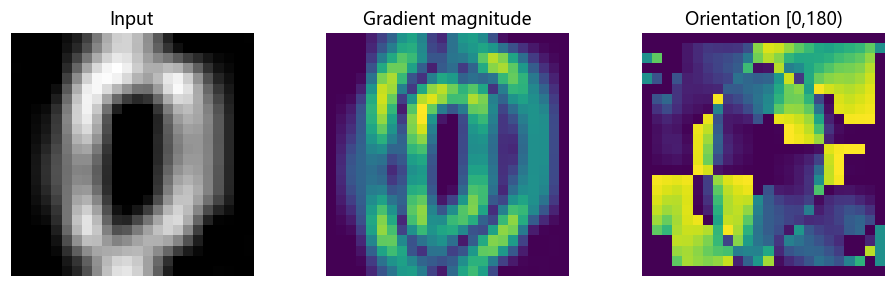

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/05_hog_process.png')

In [3]:
hog = cv2.HOGDescriptor((24, 24), (8, 8), (4, 4), (4, 4), 9)
resized = np.stack([cv2.resize(im, (24, 24), interpolation=cv2.INTER_CUBIC) for im in images])
features = np.stack([hog.compute(im).ravel() for im in resized])
gx = cv2.Sobel(resized[0], cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(resized[0], cv2.CV_32F, 0, 1, ksize=3)
magnitude, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)
print("图像张量：", resized.shape, "HOG 特征：", features.shape)
print("特征前 16 项：", np.round(features[0, :16], 3))
print("局部水平梯度：\n", np.round(gx[8:12, 8:12], 1))
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, im, title in zip(axs, [resized[0], magnitude, angle % 180], ["Input", "Gradient magnitude", "Orientation [0,180)"]):
    ax.imshow(im, cmap="gray" if title == "Input" else "viridis"); ax.set_title(title); ax.axis("off")
save_figure("05_hog_process.png")


## 3. 拟合分类器与独立测试

标准化器和 SVM 都只拟合训练集；测试集只用于评价。`LinearSVC` 的输出是决策分数，不能直接当作概率。


HOG + SVM 测试准确率：0.984


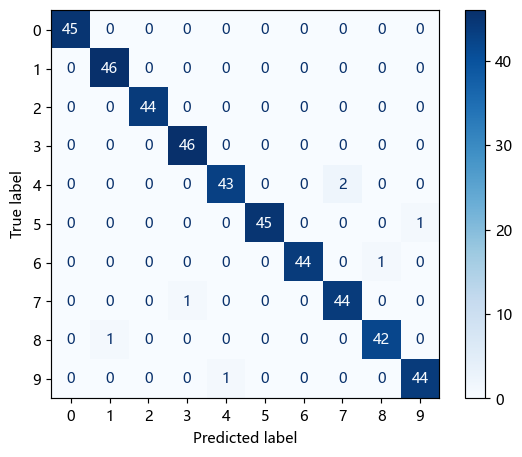

In [4]:
classifier = make_pipeline(StandardScaler(), LinearSVC(C=.2, max_iter=5000, random_state=42))
classifier.fit(features[train_idx], digits.target[train_idx])
prediction = classifier.predict(features[test_idx])
test_accuracy = accuracy_score(digits.target[test_idx], prediction)
print(f"HOG + SVM 测试准确率：{test_accuracy:.3f}")
ConfusionMatrixDisplay.from_predictions(digits.target[test_idx], prediction, cmap="Blues")
save_figure("05_hog_confusion.png")
assert test_accuracy > .85, "准确率异常低：请检查输入、标签和特征流程。"


## 4. 查看错误，而不只看一个数字

下面优先展示误分类输入。它们可能字形模糊或与其他类别相似。
分类器为整张裁剪图输出一个类别；若要在大图中检测，需要增加候选区域/滑动窗口和去重。


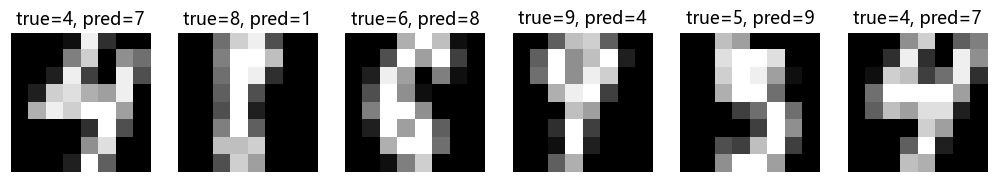

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/05_hog_errors.png')

In [5]:
wrong = np.flatnonzero(prediction != digits.target[test_idx])
selected = wrong[:6] if len(wrong) else np.arange(6)
fig, axs = plt.subplots(1, len(selected), figsize=(12, 3), squeeze=False)
for ax, k in zip(axs[0], selected):
    ax.imshow(images[test_idx[k]], cmap="gray")
    ax.set_title(f"true={digits.target[test_idx[k]]}, pred={prediction[k]}"); ax.axis("off")
save_figure("05_hog_errors.png")


## 5. Haar 级联：在照片中搜索窗口

Viola–Jones 方法把 Haar 矩形特征、积分图和级联分类器结合起来。OpenCV 自带的 XML 是已训练模型。
下面用真实篮球照片演示；远处、遮挡或非正面人脸可能漏检。画出的框必须人工复核，不应把“没有检出”理解为“没有人”。


检测框数量： 2 ；这是模型预测，不是真值标注。
输入灰度局部矩阵：
 [[82 82 68 68 69 69]
 [90 99 66 66 67 67]
 [64 64 66 67 67 67]
 [64 64 65 66 67 68]]


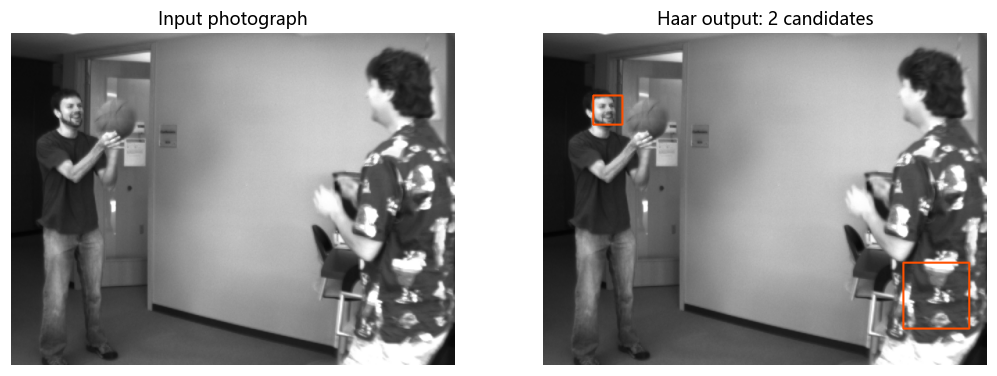

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/05_haar_photo.png')

In [6]:
photo_path = ROOT / "assets/photos/basketball1.png"
bgr = cv2.imread(str(photo_path))
if bgr is None:
    raise FileNotFoundError(f"缺少课程随附照片：{photo_path}")
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if cascade.empty():
    raise RuntimeError("OpenCV 安装中缺少 Haar 模型，请重新安装 requirements.txt。")
faces = cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(12, 12))
result = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
for x, y, w, h in faces:
    cv2.rectangle(result, (x, y), (x+w, y+h), (255, 80, 0), 2)
print("检测框数量：", len(faces), "；这是模型预测，不是真值标注。")
print("输入灰度局部矩阵：\n", gray[:4, :6])
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axs[0].set_title("Input photograph")
axs[1].imshow(result); axs[1].set_title(f"Haar output: {len(faces)} candidates")
for ax in axs: ax.axis("off")
save_figure("05_haar_photo.png")


## 6. 方法边界、练习与来源

| 方法 | 学习的内容 | 优点 | 主要局限 |
|---|---|---|---|
| Haar 级联 | 从矩形特征构建级联分类器 | CPU 快、模型小 | 正面/姿态/尺度变化敏感 |
| HOG + SVM | 梯度描述子 + 判别边界 | 特征可解释 | 大幅形变、复杂背景较困难 |
| DPM | 多部件与空间形变 | 建模物体部件布局 | 训练/推理复杂；本课不把简单 HOG 当作 DPM |

练习：改变 HOG 方向箱数量，记录特征长度与独立测试准确率；降低图片亮度后重新评价；改变 Haar 的 `minNeighbors`，观察误检与漏检。

来源：[OpenCV HOGDescriptor](https://docs.opencv.org/4.x/d5/d33/structcv_1_1HOGDescriptor.html)、[OpenCV 级联检测教程](https://docs.opencv.org/4.x/db/d28/tutorial_cascade_classifier.html)、[scikit-learn digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)。数据与照片许可见项目 `THIRD_PARTY.md`。


## HOG + 线性 SVM：图像如何变成特征向量

原始像素矩阵: (8, 8) → 缩放图: (24, 24) → HOG 向量: (900,)


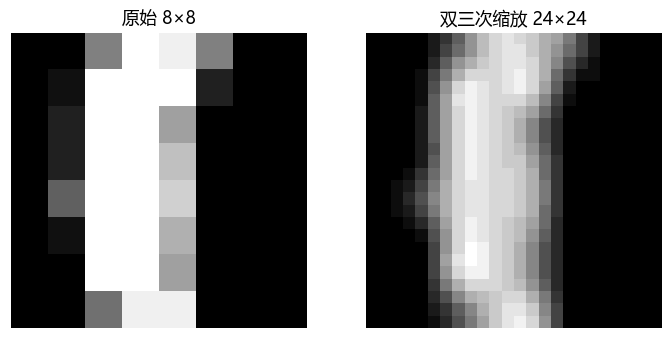

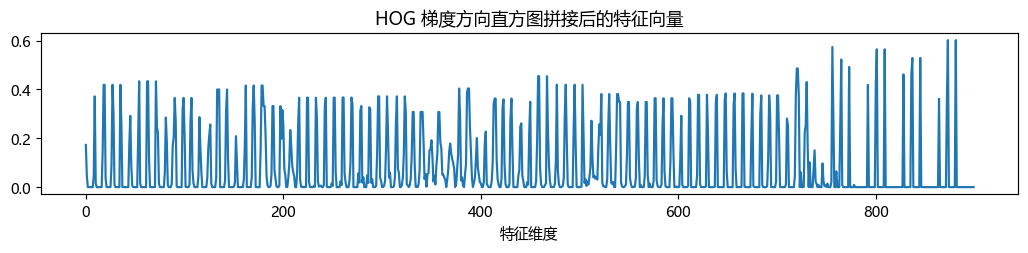

本样本预测: 1 真实标签: 1


In [7]:
sample = int(test_idx[0])
raw = digits.images[sample].astype(np.uint8)
resized_one = cv2.resize(raw, (24, 24), interpolation=cv2.INTER_CUBIC)
hog_vector = hog.compute(resized_one).reshape(-1)
print("原始像素矩阵:", raw.shape, "→ 缩放图:", resized_one.shape, "→ HOG 向量:", hog_vector.shape)
fig, axs = plt.subplots(1, 2, figsize=(8, 4)); axs[0].imshow(raw, cmap="gray"); axs[0].set_title("原始 8×8"); axs[1].imshow(resized_one, cmap="gray"); axs[1].set_title("双三次缩放 24×24");
for ax in axs: ax.axis("off")
plt.show(); plt.figure(figsize=(12, 2)); plt.plot(hog_vector); plt.title("HOG 梯度方向直方图拼接后的特征向量"); plt.xlabel("特征维度"); plt.show()
print("本样本预测:", int(classifier.predict(features[sample:sample+1])[0]), "真实标签:", int(digits.target[sample]))